In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA627249/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,Organism,Platform,ReleaseDate,create_date,version,samp_collect_device,samp_size,Sample.Name,sample_type,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>
1,SRR11586733,AMPLICON,493,12090737,PRJNA627249,SAMN14657072,Metagenome or environmental,7355033,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,21,DC027,Saliva,SRP257857
2,SRR11586734,AMPLICON,183,2749588,PRJNA627249,SAMN14657071,Metagenome or environmental,1602208,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,20,DC020,Saliva,SRP257857
3,SRR11586735,AMPLICON,217,6759522,PRJNA627249,SAMN14657142,Metagenome or environmental,3790858,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,91,DC172,Saliva,SRP257857
4,SRR11586736,AMPLICON,375,7206060,PRJNA627249,SAMN14657141,Metagenome or environmental,4411957,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,90,DC171,Saliva,SRP257857
5,SRR11586737,AMPLICON,453,12841682,PRJNA627249,SAMN14657140,Metagenome or environmental,8059578,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,89,DC167,Saliva,SRP257857
6,SRR11586738,AMPLICON,234,4135841,PRJNA627249,SAMN14657139,Metagenome or environmental,2383345,MAKERERE UNIVERSITY COLLEGE OF HEALTH SCIENCE,2018-01-02/2018-05-30,⋯,human oral metagenome,ILLUMINA,2020-05-20T00:00:00Z,2020-04-22T08:12:00Z,1,Spitting into a plastic tube,88,DC161,Saliva,SRP257857


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "isolation_source"               "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "create_date"                   
[31] "version"                        "samp_collect_device"           
[33] "samp_size"                      "Sample.Name"                   
[35] "sample_type"                    "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V6-V8',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "Microbial characteristics of dental caries in HIV positive individuals",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 80
[1] 80


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA627249,SRR11586733,DC027,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO
2,PRJNA627249,SRR11586734,DC020,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO
3,PRJNA627249,SRR11586735,DC172,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO
4,PRJNA627249,SRR11586736,DC171,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO
5,PRJNA627249,SRR11586737,DC167,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO
6,PRJNA627249,SRR11586738,DC161,NA,NA,NA,V6-V8,ILLUMINA,Uganda,saliva,2020-05-20T00:00:00Z,NA,Microbial characteristics of dental caries in HIV positive individuals,YES,NA,NO


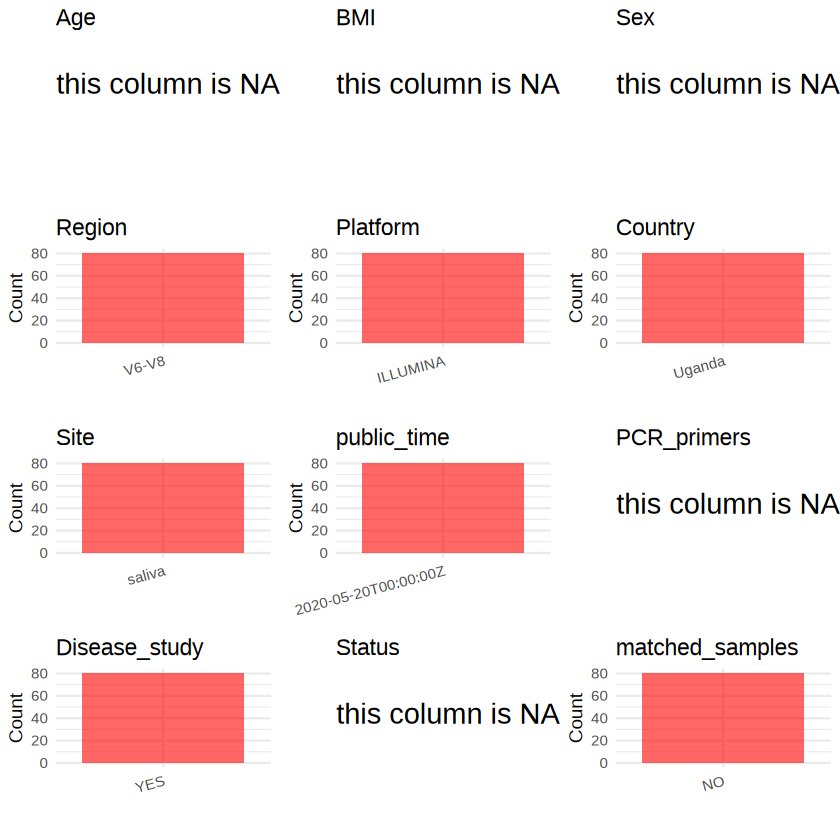

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA627249/metadata.csv", quote = T)